In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

warnings.filterwarnings("ignore")

In [3]:
#Load Model Tables

df = pd.read_csv("../outputs/model_table.csv")
df.shape

(25000, 20)

In [4]:
df["registration_date"] = pd.to_datetime(df["registration_date"], errors="coerce")
df["visit_date"] = pd.to_datetime(df["visit_date"], errors="coerce")
df["billing_date"] = pd.to_datetime(df["billing_date"], errors="coerce")
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   patient_id            25000 non-null  int64         
 1   age                   25000 non-null  int64         
 2   gender                25000 non-null  str           
 3   city                  25000 non-null  str           
 4   insurance_provider    25000 non-null  str           
 5   chronic_flag          25000 non-null  int64         
 6   registration_date     25000 non-null  datetime64[us]
 7   visit_id              25000 non-null  int64         
 8   visit_date            25000 non-null  datetime64[us]
 9   department            25000 non-null  str           
 10  visit_type            25000 non-null  str           
 11  length_of_stay_hours  25000 non-null  float64       
 12  risk_score            25000 non-null  str           
 13  doctor_id             25000

In [5]:
df.describe(include="all").T 

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
patient_id,25000.0,NaN,NaN,NaN,2509.51536,1.0,1249.0,2505.0,3764.0,5000.0,1448.68904
age,25000.0,NaN,NaN,NaN,44.76832,1.0,33.0,45.0,57.0,90.0,17.784232
gender,25000,2,F,12739,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,25000,6,Hyderabad,4370,NaN,NaN,NaN,NaN,NaN,NaN,NaN
insurance_provider,25000,4,MediCareX,6532,NaN,NaN,NaN,NaN,NaN,NaN,NaN
chronic_flag,25000.0,NaN,NaN,NaN,0.5026,0.0,0.0,1.0,1.0,1.0,0.500003
registration_date,25000,NaN,NaN,NaN,2025-07-18 16:17:11.040000,2025-01-20 00:00:00,2025-04-16 00:00:00,2025-07-19 00:00:00,2025-10-19 00:00:00,2026-01-20 00:00:00,NaN
visit_id,25000.0,NaN,NaN,NaN,12500.5,1.0,6250.75,12500.5,18750.25,25000.0,7217.022701
visit_date,25000,NaN,NaN,NaN,2025-07-21 15:25:51.744000,2025-01-20 00:00:00,2025-04-21 00:00:00,2025-07-21 00:00:00,2025-10-21 00:00:00,2026-01-20 00:00:00,NaN
department,25000,6,General,4228,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
#distribution analysis

#Missing value analysis


In [7]:
#overall null check

df.isnull().sum().sort_values(ascending=False)

approved_amount         1318
payment_days             790
patient_id                 0
age                        0
city                       0
gender                     0
insurance_provider         0
chronic_flag               0
visit_date                 0
department                 0
registration_date          0
visit_id                   0
length_of_stay_hours       0
visit_type                 0
risk_score                 0
doctor_id                  0
billed_amount              0
bill_id                    0
claim_status               0
billing_date               0
dtype: int64

In [8]:
df[["approved_amount", "payment_days", "length_of_stay_hours"]].isnull().sum()

approved_amount         1318
payment_days             790
length_of_stay_hours       0
dtype: int64

In [9]:
#check A - Paid claims should always have an approved amount


df[
    (df["claim_status"] == "Paid") &
    (df["approved_amount"].isna())
].shape

(817, 20)

In [10]:
#check-B payment days missing breakdown by claim status
df[df["payment_days"].isna()]["claim_status"].value_counts()

claim_status
Paid        459
Pending     208
Rejected    123
Name: count, dtype: int64

In [11]:
#Check - c LOS should never be negative
(df["length_of_stay_hours"]<0).sum()

np.int64(0)

In [12]:
#categorical coloumn report

print("======Department======")
print(df["department"].value_counts())
print("\n======Visit Type======")
print(df["visit_type"].value_counts())
print("\n======Insurance provider======")
print(df["insurance_provider"].value_counts())
print("\n======City======")
print(df["city"].value_counts())


======Department======
department
General        4228
ER             4220
Neurology      4165
Orthopedics    4164
Cardiology     4159
ICU            4064
Name: count, dtype: int64

======Visit Type======
visit_type
ER     8382
OPD    8381
ICU    8237
Name: count, dtype: int64

======Insurance provider======
insurance_provider
MediCareX     6532
CareOne       6283
HealthPlus    6220
SecureLife    5965
Name: count, dtype: int64

======City======
city
Hyderabad    4370
Pune         4221
Bangalore    4205
Mumbai       4122
Delhi        4107
Chennai      3975
Name: count, dtype: int64


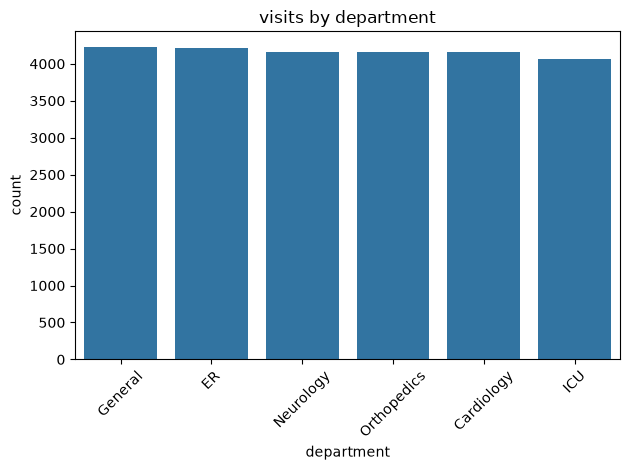

In [13]:
# Barchart showing visits by department
sns.countplot(data=df, x="department", order=df["department"].value_counts().index)
plt.xticks(rotation=45)
plt.title("visits by department")
plt.tight_layout()
plt.show()

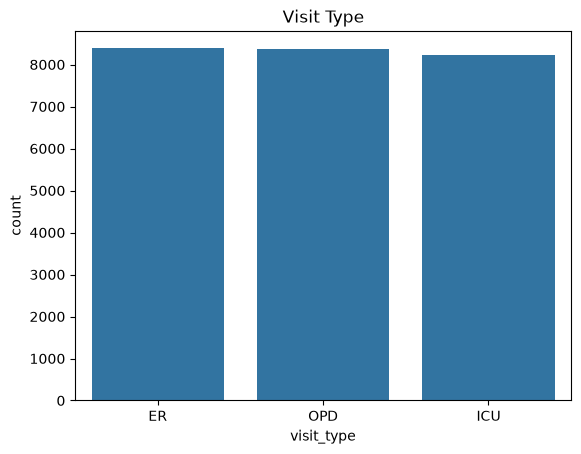

In [14]:
#Visits by type
sns.countplot(data=df, x = "visit_type", order=df["visit_type"].value_counts().index)
plt.title("Visit Type")
plt.show()

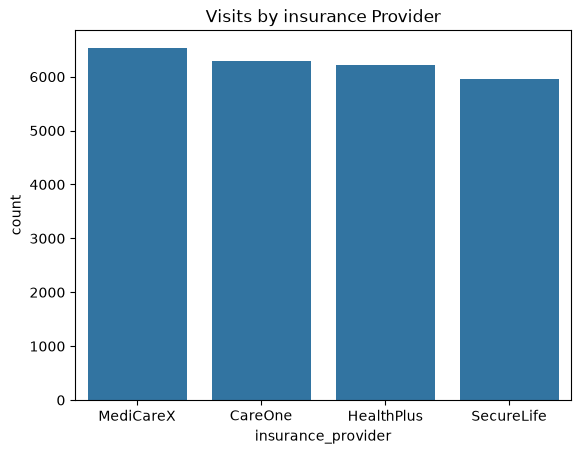

In [15]:
sns.countplot(data=df, x = "insurance_provider", order=df["insurance_provider"].value_counts().index)
plt.title("Visits by insurance Provider")
plt.show()

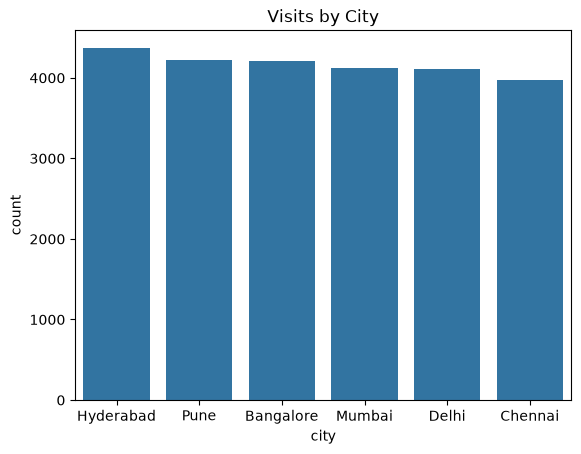

In [16]:
sns.countplot(data=df, x = "city", order=df["city"].value_counts().index)
plt.title("Visits by City")
plt.show()

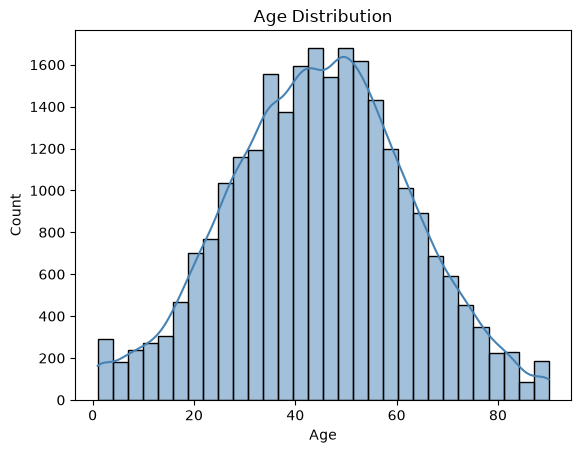

count    25000.00
mean        44.77
std         17.78
min          1.00
25%         33.00
50%         45.00
75%         57.00
max         90.00
Name: age, dtype: float64


In [17]:
#Age distribution
sns.histplot(df["age"], bins=30, kde=True, color="steelblue")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.show()
print(df["age"].describe().round(2))

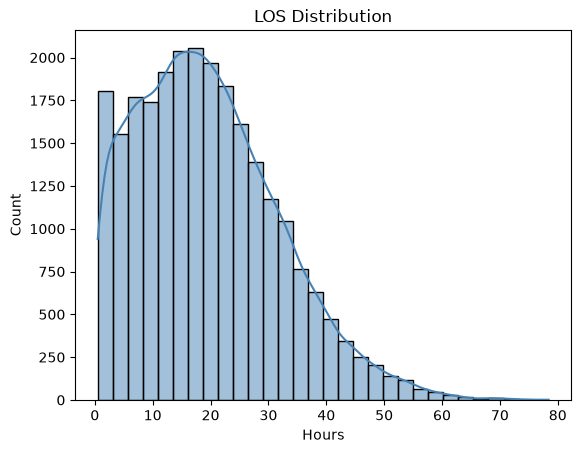

count    25000.00
mean        19.55
std         12.31
min          0.50
25%          9.96
50%         18.20
75%         27.31
max         78.42
Name: length_of_stay_hours, dtype: float64


In [18]:
#length of stay distribution
sns.histplot(df["length_of_stay_hours"], bins=30, kde=True, color="steelblue")
plt.title("LOS Distribution")
plt.xlabel("Hours")
plt.show()
print(df["length_of_stay_hours"].describe().round(2))

In [19]:
IQR = 27.31 - 9.96
print(IQR)

17.349999999999998


In [20]:
#upper fence
#outlier(value beyond and considered an outlier)
#jhons variable = 1.5(universal multiplier)
upper_fence = 27.31 + (1.5*17.35)
print(upper_fence)

53.335


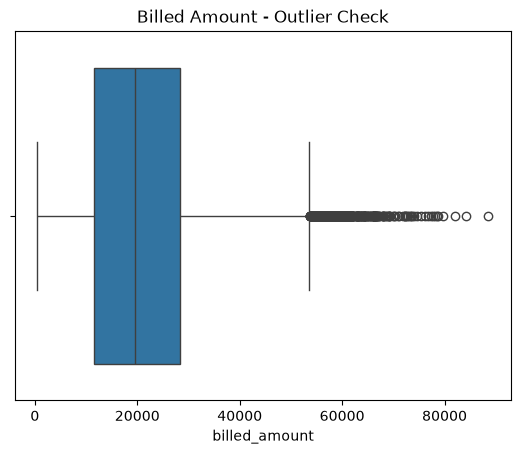

In [21]:
#outlier detection

sns.boxplot(x=df["billed_amount"])
plt.title("Billed Amount - Outlier Check")
plt.show()

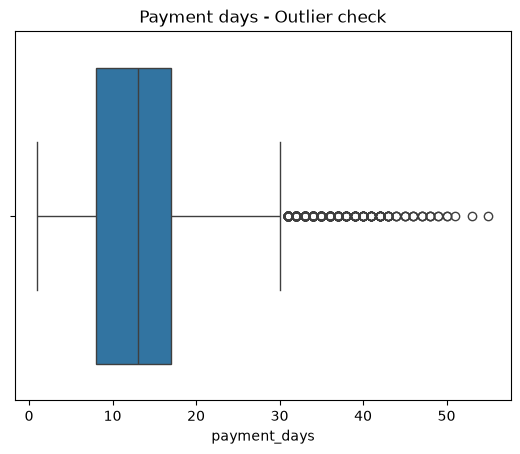

In [22]:
sns.boxplot(x=df["payment_days"])
plt.title("Payment days - Outlier check")
plt.show()

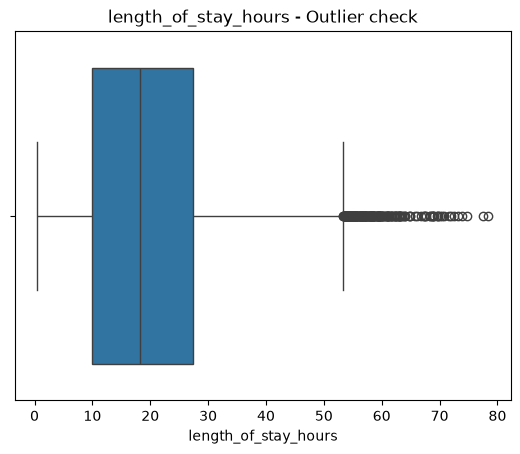

In [23]:
sns.boxplot(x=df["length_of_stay_hours"])
plt.title("length_of_stay_hours - Outlier check")
plt.show()

In [24]:
for col in ["length_of_stay_hours", "billed_amount", "payment_days"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3-Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((df[col]<lower) | (df[col]>upper)).sum()
    print(f"{col}")
    print(f"Q1 = {Q1:.1} | Q3 = {Q3:.1f} | IQR = {IQR:.1f}" )
    print(f"Lower bound = {lower:.1f} | Upper bound = {upper:.1f}")
    print(f"Outliers = {n_out} rows")
    print()

length_of_stay_hours
Q1 = 1e+01 | Q3 = 27.3 | IQR = 17.4
Lower bound = -16.1 | Upper bound = 53.3
Outliers = 256 rows

billed_amount
Q1 = 1e+04 | Q3 = 28398.1 | IQR = 16815.6
Lower bound = -13641.0 | Upper bound = 53621.5
Outliers = 373 rows

payment_days
Q1 = 8e+00 | Q3 = 17.0 | IQR = 9.0
Lower bound = -5.5 | Upper bound = 30.5
Outliers = 509 rows



In [25]:
#feature Correlations
#only works on numerical features

In [26]:
#encode target for correlation analysis
df["risk_numeric"] = df["risk_score"].map(
    {"Low": 0, "Medium": 1, "High":2}
)

df["claim_numeric"] = df["claim_status"].map(
    {"Paid": 0, "Pending": 1, "Rejected":2}
)
print("risk_numeric :", {"Low": 0, "Medium": 1, "High": 2})
print("claim_numeric :", {"Paid": 0, "Pending": 1, "Rejected": 2})


risk_numeric : {'Low': 0, 'Medium': 1, 'High': 2}
claim_numeric : {'Paid': 0, 'Pending': 1, 'Rejected': 2}


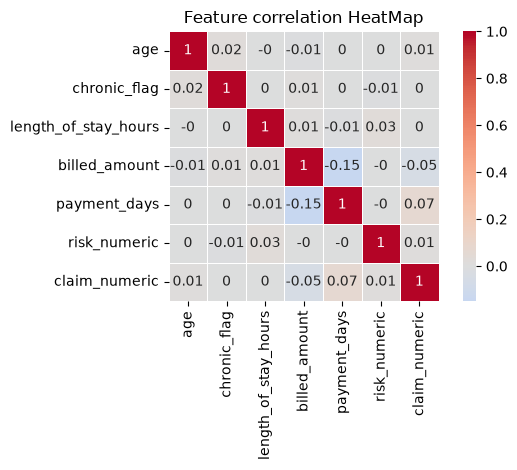

In [27]:
#Full corellation heat map

numeric_cols = [
    "age",
    "chronic_flag",
    "length_of_stay_hours",
    "billed_amount",
    "payment_days",
    "risk_numeric",
    "claim_numeric"
]
corr = df[numeric_cols].corr().round(2)
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, linewidth=0.5, square=True)
plt.title("Feature correlation HeatMap")
plt.tight_layout()
plt.show()

In [28]:
corr_risk = corr["risk_numeric"].drop("risk_numeric")

print("correlation with risk_score sorted:")
print(corr_risk.sort_values(ascending=False).round(3))

correlation with risk_score sorted:
length_of_stay_hours    0.03
claim_numeric           0.01
billed_amount          -0.00
age                     0.00
payment_days           -0.00
chronic_flag           -0.01
Name: risk_numeric, dtype: float64


In [29]:
corr_claim = corr["claim_numeric"].drop("claim_numeric")

print("correlation with claim_status sorted:")
print(corr_claim.sort_values(ascending=False).round(3))

correlation with claim_status sorted:
payment_days            0.07
age                     0.01
risk_numeric            0.01
chronic_flag            0.00
length_of_stay_hours    0.00
billed_amount          -0.05
Name: claim_numeric, dtype: float64


In [30]:
df.head()

,patient_id,age,gender,city,insurance_provider,chronic_flag,registration_date,visit_id,visit_date,department,...,risk_score,doctor_id,bill_id,billed_amount,approved_amount,claim_status,payment_days,billing_date,risk_numeric,claim_numeric
0,3993,9,M,Hyderabad,HealthPlus,1,2025-10-18,684,2025-01-20,General,...,Low,137,684,36721.68,36721.68,Paid,19.0,2025-08-15,0,0
1,76,59,M,Delhi,HealthPlus,0,2025-07-09,1412,2025-01-20,General,...,Medium,109,1412,8365.47,4189.20,Pending,26.0,2025-11-14,1,1
2,3393,43,M,Hyderabad,HealthPlus,0,2025-07-10,1510,2025-01-20,ICU,...,Medium,135,1510,16529.35,0.00,Rejected,7.0,2025-04-24,1,2
3,1998,29,M,Bangalore,MediCareX,1,2025-04-22,1549,2025-01-20,Cardiology,...,Medium,179,1549,61827.63,61827.63,Paid,1.0,2025-10-17,1,0
4,3500,38,M,Hyderabad,CareOne,1,2025-08-02,2275,2025-01-20,Orthopedics,...,Low,107,2275,5860.51,4897.65,Pending,28.0,2025-08-05,0,1


str
<ArrowStringArray>
['Paid', 'Pending', 'Rejected']
Length: 3, dtype: str


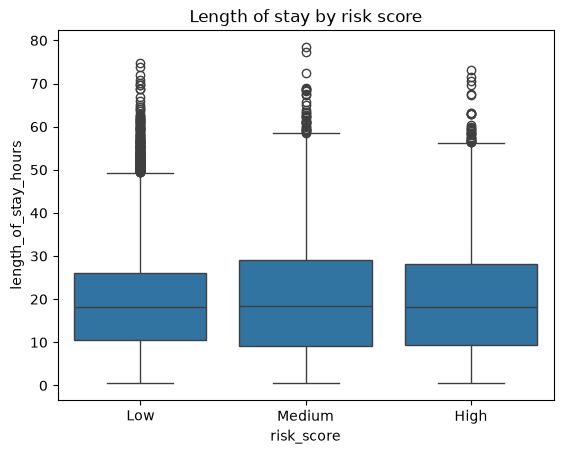


Mean LOS by risk score:
risk_score
High      19.758576
Low       19.151184
Medium    20.078663
Name: length_of_stay_hours, dtype: float64 2


In [33]:
sns.boxplot(data=df, x = "risk_score", y="length_of_stay_hours", order = ["Low", "Medium", "High"])
plt.title("Length of stay by risk score")
plt.show()
print("\nMean LOS by risk score:")
print(df.groupby("risk_score")["length_of_stay_hours"].mean(),round(2))


rejection rate by insurance provider(%)
insurance_provider
SecureLife    15.7
MediCareX     15.2
HealthPlus    15.0
CareOne       14.9
Name: is_rejected, dtype: float64


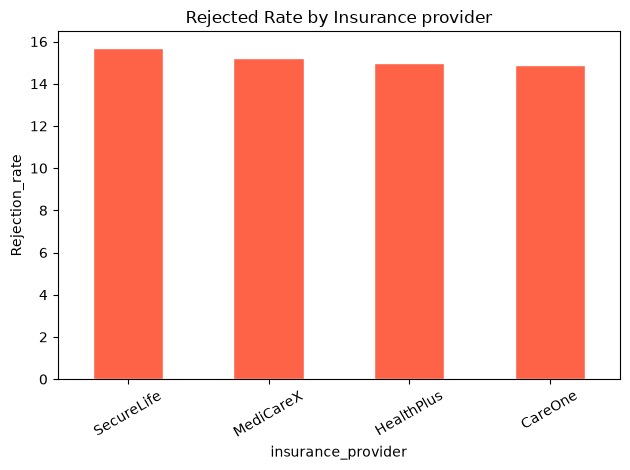

In [38]:
df["is_rejected"] = (df["claim_status"] == "Rejected").astype(int)
rej_rate = (df.groupby("insurance_provider")["is_rejected"]
            .mean()
            .sort_values(ascending=False)
            .mul(100)
            .round(1))
print("rejection rate by insurance provider(%)")

print(rej_rate)

rej_rate.plot(kind="bar", color = "tomato", edgecolor = "white")
plt.title("Rejected Rate by Insurance provider")
plt.ylabel("Rejection_rate")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [43]:
#class imbalance and deep dive

#naive baseline - what happens if we always predict majority class

most_commom = df["risk_score"].mode()[0]
naive_acc = (df["risk_score"] == most_commom).mean() 
print(f"Majority class: '{most_commom}'")
print(f"Naive Accuracy: '{naive_acc:.1%}'")

Majority class: 'Low'
Naive Accuracy: '49.9%'


In [ ]:
#demp setup - two features only